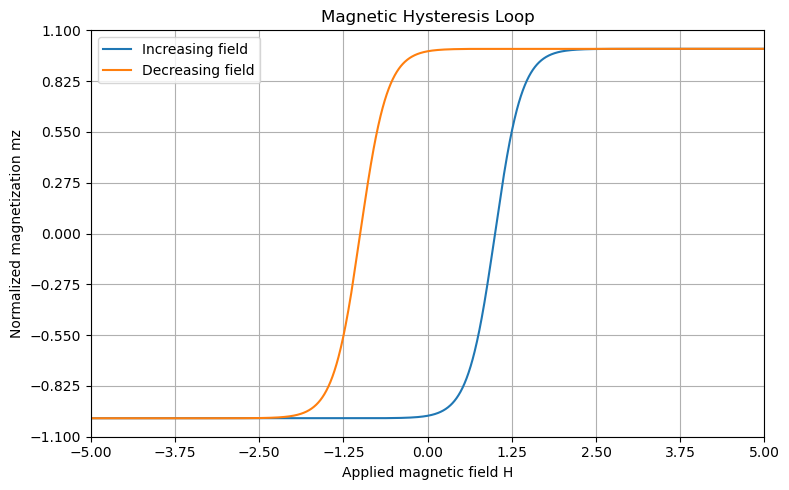

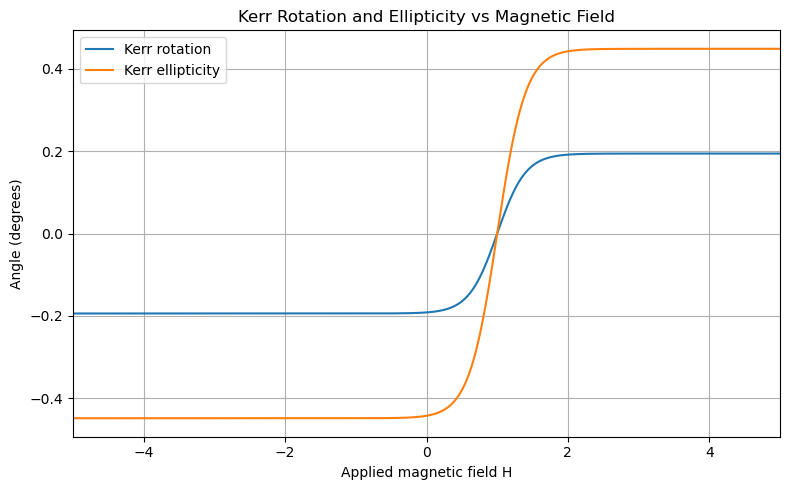

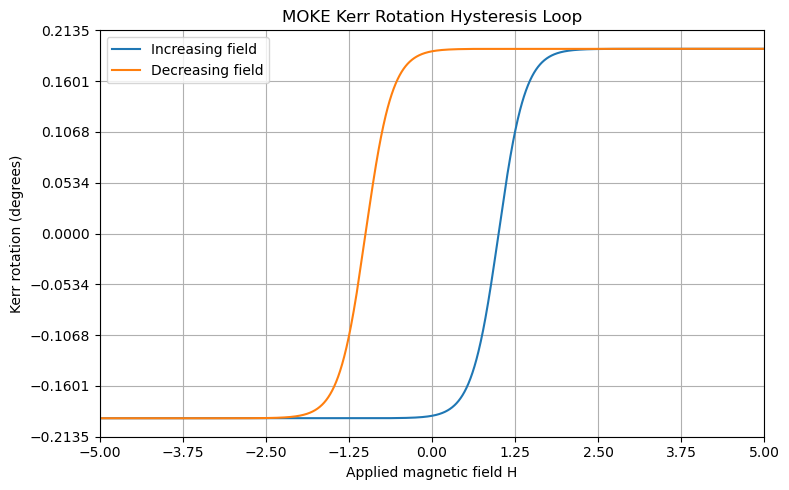

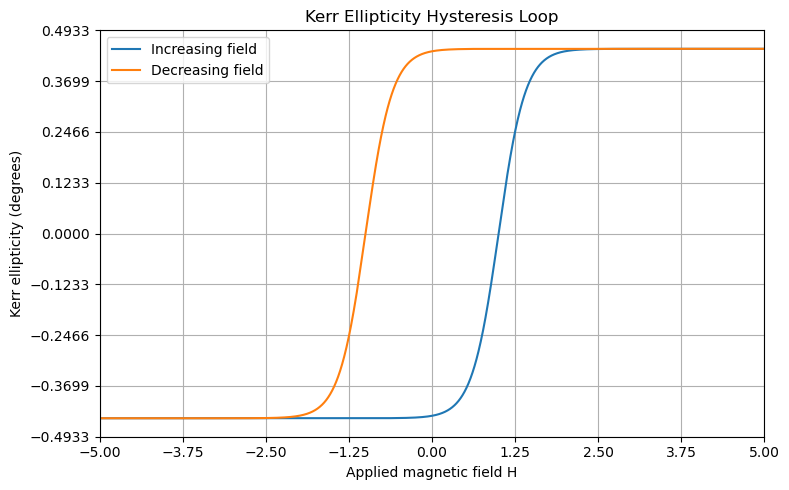

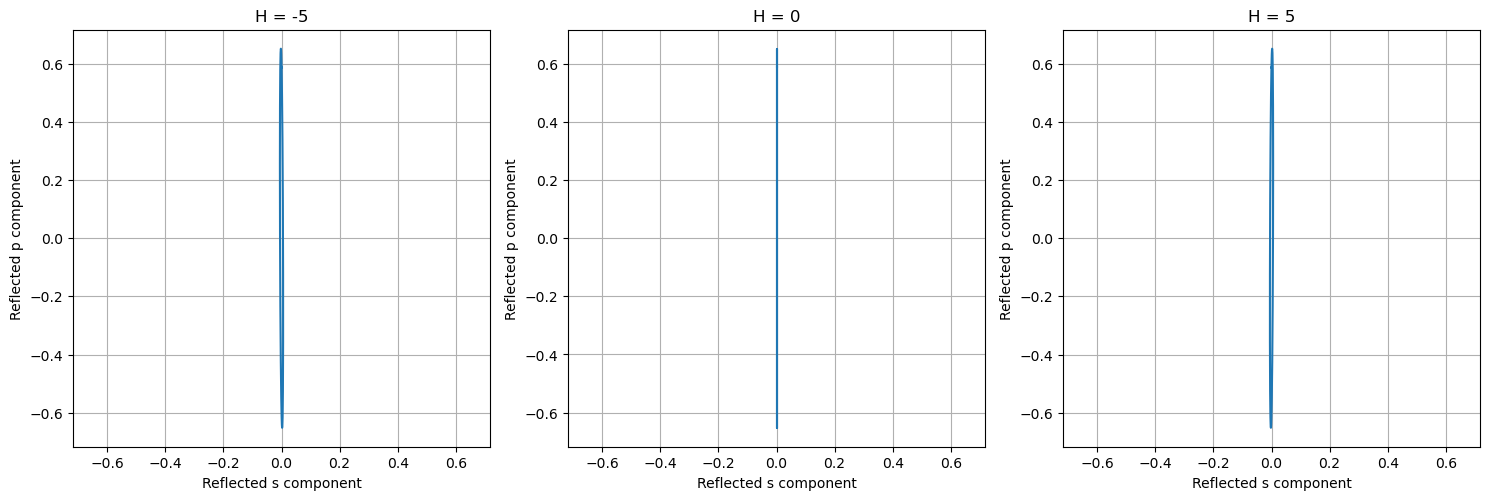


========== MOKE SIMULATION SUMMARY ==========
Wavelength             : 633.00 nm
Incidence angle        : 45.00 degrees
Film thickness         : 20.00 nm
Substrate index        : 1.5
Coercive field         : 1.0
Switching width        : 0.4
Field samples/branch   : 2000

--- Saturated Kerr response ---
Increasing branch, positive saturation: Rotation = 0.194110 degrees, Ellipticity = 0.448417 degrees
Decreasing branch, negative saturation: Rotation = -0.194110 degrees, Ellipticity = -0.448417 degrees

Simulation completed.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm

# INPUTS
# Optical parameters
WAVELENGTH = 633e-9          # (metres) Laser wavelength
INCIDENCE_ANGLE = 45.0       # (degrees) Angle of incidence
N_INCIDENT = 1.0             # Refractive index of incident medium
N_SUBSTRATE = 1.5            # Refractive index of substrate

# Magnetic film parameters

FILM_THICKNESS = 20e-9       # (metres) Cobalt film thickness 
EPSILON_D = -11.49 + 18.32j  # Diagonal dielectric constant
VOIGT_Q = 0.0283 + 0.0066j   # Magneto-optic Voigt parameter

# Magnetization direction
# Polar MOKE: magnetization perpendicular to film surface

MX = 0.0
MY = 0.0

# Magnetic hysteresis parameters

H_MIN = -5.0
H_MAX = 5.0

H_COERCIVE = 1.0             # Coercive field (model units)
SWITCHING_WIDTH = 0.4        # Controls switching sharpness

# Numerical resolution of graph

N_POINTS = 2000              # Field points per hysteresis branch
N_PHASE_POINTS = 1000        # Points for polarization ellipse
N_AXIS_TICKS = 9             # Number of axis markings

# Plot controls

SHOW_MAGNETIZATION_LOOP = True
SHOW_KERR_RESPONSE = True
SHOW_KERR_ROTATION_LOOP = True
SHOW_KERR_ELLIPTICITY_LOOP = True
SHOW_POLARIZATION_ELLIPSES = True

# Magnetic fields at which to show polarization ellipses
POLARIZATION_FIELDS = [-5.0, 0.0, 5.0]



# PHYSICAL CONSTANTS AND DERIVED OPTICAL PARAMETERS

C = 299792458.0              # Speed of light in vacuum (m/s)

def compute_derived_constants(
    wavelength,
    incidence_angle_deg,
    n_incident ):

    theta_i = np.radians(incidence_angle_deg)
    omega = 2.0 * np.pi * C / wavelength
    k0 = 2.0 * np.pi / wavelength
    kx = k0 * n_incident * np.sin(theta_i)
    
    return omega, k0, kx, theta_i

omega, k0, kx, theta_i = compute_derived_constants(
    WAVELENGTH,
    INCIDENCE_ANGLE,
    N_INCIDENT
)



# DIELECTRIC TENSOR

def get_dielectric_tensor(
    epsilon_d,
    Q,
    magnetization,
    is_magnetic=True ):

    if not is_magnetic:
        return epsilon_d * np.eye(3, dtype=complex)

    mx, my, mz = magnetization

    tensor_matrix = np.array(
        [
            [1.0, 1j * Q * mz, -1j * Q * my],

            [-1j * Q * mz, 1.0, 1j * Q * mx],

            [1j * Q * my, -1j * Q * mx, 1.0]
        ],
        dtype=complex
    )

    return epsilon_d * tensor_matrix



# BERREMAN 4 x 4 MATRIX

def berreman_matrix(eps, kx, k0):

    xi = kx / k0
    eps = np.asarray(eps, dtype=complex)
    
    exx, exy, exz = eps[0, 0], eps[0, 1], eps[0, 2]
    eyx, eyy, eyz = eps[1, 0], eps[1, 1], eps[1, 2]
    ezx, ezy, ezz = eps[2, 0], eps[2, 1], eps[2, 2]

    row0 = [
        -xi * ezx / ezz,
        1.0 - xi**2 / ezz,
        -xi * ezy / ezz,
        0.0
    ]
    row1 = [
        exx - exz * ezx / ezz,
        -xi * exz / ezz,
        exy - exz * ezy / ezz,
        0.0
    ]
    row2 = [
        0.0, 0.0, 0.0, 1.0
    ]
    row3 = [
        eyx - eyz * ezx / ezz,
        -xi * eyz / ezz,
        eyy - eyz * ezy / ezz - xi**2,
        0.0
    ]

    return np.array(
        [row0, row1, row2, row3],
        dtype=complex
    )



# TRANSFER MATRIX

def compute_transfer_matrix(k0, thickness, delta):

    return expm(1j * k0 * thickness * delta)



# INCIDENT, REFLECTED AND TRANSMITTED FIELD MATRICES

def calculate_field_matrices(
    theta_i,
    n_incident,
    n_substrate
):

    # Snell's law

    sin_theta_t = (
        n_incident * np.sin(theta_i) / n_substrate
    )

    theta_t = np.arcsin(sin_theta_t)

    cos_i = np.cos(theta_i)

    cos_t = np.cos(theta_t)


    # Incident field matrix

    L_inc = np.array(
        [
            [0, cos_i],
            [0, n_incident],
            [1, 0],
            [n_incident * cos_i, 0]
        ],
        dtype=complex
    )


    # Reflected field matrix

    L_ref = np.array(
        [
            [0, -cos_i],
            [0, n_incident],
            [1, 0],
            [-n_incident * cos_i, 0]
        ],
        dtype=complex
    )


    # Transmitted field matrix

    L_trans = np.array(
        [
            [0, cos_t],
            [0, n_substrate],
            [1, 0],
            [n_substrate * cos_t, 0]
        ],
        dtype=complex
    )

    return L_inc, L_ref, L_trans, theta_t


L_inc, L_ref, L_trans, theta_t = calculate_field_matrices(
    theta_i,
    N_INCIDENT,
    N_SUBSTRATE
)


# ==============================================================
# 8. REFLECTION COEFFICIENT CALCULATION
# ==============================================================

def calculate_reflection(mz_value):

    # Magnetization vector

    magnetization = (
        MX,
        MY,
        mz_value
    )


    # Dielectric tensor

    eps = get_dielectric_tensor(
        EPSILON_D,
        VOIGT_Q,
        magnetization,
        is_magnetic=True
    )


    # Berreman matrix

    delta = berreman_matrix(
        eps,
        kx,
        k0
    )


    # Transfer matrix

    T = compute_transfer_matrix(
        k0,
        FILM_THICKNESS,
        delta
    )


    # Boundary-condition matrix

    A = np.hstack(
        (
            T @ L_ref,
            -L_trans
        )
    )


    # p-polarized incident light

    incident_p = np.array(
        [[0], [1]],
        dtype=complex
    )

    b_p = -T @ L_inc @ incident_p


    # Solve boundary equations

    x_p = np.linalg.solve(A, b_p)


    # Reflected polarization amplitudes

    r_sp = x_p[0, 0]

    r_pp = x_p[1, 0]


    return r_sp, r_pp


# ==============================================================
# 9. KERR ROTATION AND ELLIPTICITY
# ==============================================================

def calculate_kerr_from_mz(mz_value):

    # Calculate reflected amplitudes

    r_sp, r_pp = calculate_reflection(mz_value)


    # Complex Kerr ratio

    rho = r_sp / r_pp

    a = np.real(rho)

    b = np.imag(rho)


    # Kerr rotation

    theta_K = 0.5 * np.arctan2(
        2.0 * a,
        1.0 - a**2 - b**2
    )


    # Kerr ellipticity

    argument = (
        2.0 * b / (1.0 + a**2 + b**2)
    )

    # Protect against tiny floating-point overshoots

    argument = np.clip(argument, -1.0, 1.0)

    eta_K = 0.5 * np.arcsin(argument)


    return (
        np.degrees(theta_K),
        np.degrees(eta_K)
    )


# ==============================================================
# 10. MAGNETIZATION HYSTERESIS MODEL
# ==============================================================

# Increasing magnetic field: negative to positive

H_up = np.linspace(
    H_MIN,
    H_MAX,
    N_POINTS
)


# Decreasing magnetic field: positive to negative

H_down = np.linspace(
    H_MAX,
    H_MIN,
    N_POINTS
)


# Magnetization during increasing field

mz_up = np.tanh(
    (H_up - H_COERCIVE) / SWITCHING_WIDTH
)


# Magnetization during decreasing field

mz_down = np.tanh(
    (H_down + H_COERCIVE) / SWITCHING_WIDTH
)


# ==============================================================
# 11. CALCULATE KERR RESPONSE FOR BOTH BRANCHES
# ==============================================================

def calculate_branch_kerr(magnetization):

    rotation = []

    ellipticity = []

    for mz_value in magnetization:

        theta, eta = calculate_kerr_from_mz(
            mz_value
        )

        rotation.append(theta)

        ellipticity.append(eta)


    return (
        np.array(rotation),
        np.array(ellipticity)
    )


# Increasing-field optical response

kerr_up, ellipticity_up = calculate_branch_kerr(
    mz_up
)


# Decreasing-field optical response

kerr_down, ellipticity_down = calculate_branch_kerr(
    mz_down
)


# ==============================================================
# 12. GENERAL HYSTERESIS PLOTTING FUNCTION
# ==============================================================

def plot_hysteresis(
    H_up,
    H_down,
    y_up,
    y_down,
    title,
    ylabel,
    y_limit
):

    fig, ax = plt.subplots(
        figsize=(8, 5)
    )

    ax.plot(
        H_up,
        y_up,
        label="Increasing field"
    )

    ax.plot(
        H_down,
        y_down,
        label="Decreasing field"
    )


    # Fixed axis limits for comparison

    ax.set_xlim(H_MIN, H_MAX)

    ax.set_ylim(-y_limit, y_limit)


    # Axis markings

    ax.set_xticks(
        np.linspace(
            H_MIN,
            H_MAX,
            N_AXIS_TICKS
        )
    )

    ax.set_yticks(
        np.linspace(
            -y_limit,
            y_limit,
            N_AXIS_TICKS
        )
    )


    ax.set_xlabel("Applied magnetic field H")

    ax.set_ylabel(ylabel)

    ax.set_title(title)

    ax.legend()

    ax.grid(True)

    plt.tight_layout()

    plt.show()


# ==============================================================
# 13. GRAPH 1: MAGNETIC HYSTERESIS LOOP
# ==============================================================

if SHOW_MAGNETIZATION_LOOP:

    plot_hysteresis(
        H_up,
        H_down,
        mz_up,
        mz_down,
        "Magnetic Hysteresis Loop",
        "Normalized magnetization mz",
        1.1
    )


# ==============================================================
# 14. GRAPH 2: KERR ROTATION AND ELLIPTICITY VS FIELD
# ==============================================================

if SHOW_KERR_RESPONSE:

    fig, ax = plt.subplots(
        figsize=(8, 5)
    )

    ax.plot(
        H_up,
        kerr_up,
        label="Kerr rotation"
    )

    ax.plot(
        H_up,
        ellipticity_up,
        label="Kerr ellipticity"
    )

    ax.set_xlim(H_MIN, H_MAX)

    ax.set_xlabel("Applied magnetic field H")

    ax.set_ylabel("Angle (degrees)")

    ax.set_title(
        "Kerr Rotation and Ellipticity vs Magnetic Field"
    )

    ax.legend()

    ax.grid(True)

    plt.tight_layout()

    plt.show()


# ==============================================================
# 15. GRAPH 3: KERR ROTATION HYSTERESIS LOOP
# ==============================================================

if SHOW_KERR_ROTATION_LOOP:

    rotation_limit = 1.1 * max(
        np.max(np.abs(kerr_up)),
        np.max(np.abs(kerr_down))
    )

    plot_hysteresis(
        H_up,
        H_down,
        kerr_up,
        kerr_down,
        "MOKE Kerr Rotation Hysteresis Loop",
        "Kerr rotation (degrees)",
        rotation_limit
    )


# ==============================================================
# 16. GRAPH 4: KERR ELLIPTICITY HYSTERESIS LOOP
# ==============================================================

if SHOW_KERR_ELLIPTICITY_LOOP:

    ellipticity_limit = 1.1 * max(
        np.max(np.abs(ellipticity_up)),
        np.max(np.abs(ellipticity_down))
    )

    plot_hysteresis(
        H_up,
        H_down,
        ellipticity_up,
        ellipticity_down,
        "Kerr Ellipticity Hysteresis Loop",
        "Kerr ellipticity (degrees)",
        ellipticity_limit
    )


# ==============================================================
# 17. REFLECTED POLARIZATION ELLIPSE
# ==============================================================

def get_reflected_field(mz_value):

    return calculate_reflection(mz_value)


if SHOW_POLARIZATION_ELLIPSES:

    t = np.linspace(
        0,
        2.0 * np.pi,
        N_PHASE_POINTS
    )


    fig, axes = plt.subplots(
        1,
        len(POLARIZATION_FIELDS),
        figsize=(5 * len(POLARIZATION_FIELDS), 5)
    )

    # Handle the case of only one selected field

    axes = np.atleast_1d(axes)


    for ax, H_value in zip(
        axes,
        POLARIZATION_FIELDS
    ):

        # Use the reversible magnetization model
        # for these selected-field illustrations

        mz_value = np.tanh(
            H_value / max(SWITCHING_WIDTH, 1e-12)
        )

        r_sp, r_pp = get_reflected_field(
            mz_value
        )


        # Time-varying reflected electric-field components

        E_s = np.real(
            r_sp * np.exp(1j * t)
        )

        E_p = np.real(
            r_pp * np.exp(1j * t)
        )


        ax.plot(
            E_s,
            E_p
        )

        ax.set_title(
            f"H = {H_value:g}"
        )

        ax.set_xlabel(
            "Reflected s component"
        )

        ax.set_ylabel(
            "Reflected p component"
        )

        ax.grid(True)

        # Equal scaling is necessary to see the true ellipse shape

        max_amplitude = max(
            np.max(np.abs(E_s)),
            np.max(np.abs(E_p)),
            1e-8
        )

        ax.set_xlim(
            -1.1 * max_amplitude,
            1.1 * max_amplitude
        )

        ax.set_ylim(
            -1.1 * max_amplitude,
            1.1 * max_amplitude
        )

        ax.set_aspect(
            "equal",
            adjustable="box"
        )


    plt.tight_layout()

    plt.show()


# ==============================================================
# 18. PRINT SIMULATION SUMMARY
# ==============================================================

print("\n========== MOKE SIMULATION SUMMARY ==========")

print(f"Wavelength             : {WAVELENGTH * 1e9:.2f} nm")

print(f"Incidence angle        : {INCIDENCE_ANGLE:.2f} degrees")

print(f"Film thickness         : {FILM_THICKNESS * 1e9:.2f} nm")

print(f"Substrate index        : {N_SUBSTRATE}")

print(f"Coercive field         : {H_COERCIVE}")

print(f"Switching width        : {SWITCHING_WIDTH}")

print(f"Field samples/branch   : {N_POINTS}")


print("\n--- Saturated Kerr response ---")

print(
    f"Increasing branch, positive saturation: "
    f"Rotation = {kerr_up[-1]:.6f} degrees, "
    f"Ellipticity = {ellipticity_up[-1]:.6f} degrees"
)

print(
    f"Decreasing branch, negative saturation: "
    f"Rotation = {kerr_down[-1]:.6f} degrees, "
    f"Ellipticity = {ellipticity_down[-1]:.6f} degrees"
)

print("\nSimulation completed.")
